In [1]:
# ============================================
# INFRASCAN - MILESTONE 2
# Environment Setup
# ============================================

import os
import sys
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import cv2
import sklearn

PROJECT_DIR = "/content/InfraScan"
DATASET_DIR = os.path.join(PROJECT_DIR, "datasets")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "milestone_2_results")

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Python Version:", sys.version)
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("OpenCV:", cv2.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nProject directory exists:", os.path.exists(PROJECT_DIR))
print("Dataset directory exists:", os.path.exists(DATASET_DIR))
print("Output directory:", OUTPUT_DIR)

Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
NumPy: 2.1.3
Pandas: 2.2.3
OpenCV: 4.14.0
Scikit-learn: 1.6.1

Project directory exists: True
Dataset directory exists: False
Output directory: /content/InfraScan/milestone_2_results


In [2]:
import os

PROJECT_DIR = "/content/InfraScan"

print("Project directory contents:\n")

for item in os.listdir(PROJECT_DIR):
    path = os.path.join(PROJECT_DIR, item)

    if os.path.isdir(path):
        print(f"[DIR]  {item}/")
    else:
        print(f"[FILE] {item}")

Project directory contents:

[DIR]  milestone_2_results/


In [3]:
import os

print("Checking common dataset locations:\n")

locations = [
    "/content/InfraScan/datasets",
    "/content/datasets",
    "/content/drive/MyDrive/InfraScan/datasets"
]

for path in locations:
    print(path, "->", os.path.exists(path))

Checking common dataset locations:

/content/InfraScan/datasets -> False
/content/datasets -> False
/content/drive/MyDrive/InfraScan/datasets -> False


In [4]:
from google.colab import drive
drive.mount('/content/drive')

import os
import zipfile

DATASET_DIR = "/content/drive/MyDrive/InfraScan/datasets"

print("Drive connected:", os.path.exists(DATASET_DIR))
print("Files:", os.listdir(DATASET_DIR))

Mounted at /content/drive
Drive connected: True
Files: ['DATA_Maguire_20180517_ALL.zip', '5y9wdsg2zt-2.zip', 'CrackForest-dataset-master.zip', 'archive.zip']


In [5]:
import os
import zipfile

for filename in os.listdir(DATASET_DIR):

    if filename.endswith(".zip"):

        filepath = os.path.join(DATASET_DIR, filename)

        print("\n" + "=" * 60)
        print("ARCHIVE:", filename)
        print("=" * 60)

        with zipfile.ZipFile(filepath, 'r') as z:

            files = z.namelist()

            print("Total entries:", len(files))
            print("\nFirst 15 entries:")

            for item in files[:15]:
                print(item)


ARCHIVE: DATA_Maguire_20180517_ALL.zip
Total entries: 2

First 15 entries:
DATA_Maguire_20180517_ALL/ReadMe_SDNET2018 .txt
DATA_Maguire_20180517_ALL/SDNET2018.zip

ARCHIVE: 5y9wdsg2zt-2.zip
Total entries: 1

First 15 entries:
Concrete Crack Images for Classification.rar

ARCHIVE: CrackForest-dataset-master.zip
Total entries: 397

First 15 entries:
CrackForest-dataset-master/
CrackForest-dataset-master/README.md
CrackForest-dataset-master/groundTruth/
CrackForest-dataset-master/groundTruth/001.mat
CrackForest-dataset-master/groundTruth/002.mat
CrackForest-dataset-master/groundTruth/003.mat
CrackForest-dataset-master/groundTruth/004.mat
CrackForest-dataset-master/groundTruth/005.mat
CrackForest-dataset-master/groundTruth/006.mat
CrackForest-dataset-master/groundTruth/007.mat
CrackForest-dataset-master/groundTruth/008.mat
CrackForest-dataset-master/groundTruth/009.mat
CrackForest-dataset-master/groundTruth/010.mat
CrackForest-dataset-master/groundTruth/011.mat
CrackForest-dataset-master/

In [6]:
#extraction environment
import os
import shutil
import zipfile
from pathlib import Path
from collections import Counter

# Project directories
PROJECT_DIR = Path("/content/InfraScan")
DATASET_DIR = PROJECT_DIR / "datasets"

DATASET_DIR.mkdir(parents=True, exist_ok=True)

# Check available storage
total, used, free = shutil.disk_usage("/content")

print("Available storage:",
      round(free / (1024**3), 2), "GB")

print("\nDataset output directory:", DATASET_DIR)

# Verify source archives
DRIVE_DATASET_DIR = Path(
    "/content/drive/MyDrive/InfraScan/datasets"
)

for file in DRIVE_DATASET_DIR.iterdir():
    if file.is_file():
        print(file.name,
              round(file.stat().st_size / (1024**2), 2),
              "MB")

Available storage: 70.06 GB

Dataset output directory: /content/InfraScan/datasets
DATA_Maguire_20180517_ALL.zip 503.81 MB
5y9wdsg2zt-2.zip 229.69 MB
CrackForest-dataset-master.zip 9.66 MB
archive.zip 1567.07 MB


In [7]:
from collections import Counter
import zipfile
import io

archive_path = DRIVE_DATASET_DIR / "archive.zip"

with zipfile.ZipFile(archive_path, "r") as z:

    entries = z.infolist()

    print("CRACK500 total entries:", len(entries))

    extensions = Counter()
    folders = Counter()

    for item in entries:

        if item.is_dir():
            continue

        path = Path(item.filename)

        extensions[path.suffix.lower()] += 1

        if len(path.parts) > 1:
            folders[path.parts[1]] += 1

    print("\nFile extensions:")
    print(extensions)

    print("\nTop-level subfolders:")
    for folder, count in folders.most_common(20):
        print(folder, ":", count)

CRACK500 total entries: 10487

File extensions:
Counter({'.png': 4992, '.jpg': 3868, '.mat': 1124, '.txt': 503})

Top-level subfolders:
traincrop : 3792
fphb_testresult : 2248
testcrop : 2248
traindata : 800
valcrop : 696
testdata : 600
valdata : 100
test.txt : 1
train.txt : 1
val.txt : 1


In [8]:
#Inspect CRACK500 annotations
import zipfile
from collections import defaultdict, Counter

archive_path = (
    "/content/drive/MyDrive/InfraScan/datasets/archive.zip"
)

with zipfile.ZipFile(archive_path, "r") as z:

    folders = [
        "CRACK500/traindata/",
        "CRACK500/valdata/",
        "CRACK500/testdata/",
        "CRACK500/traincrop/",
        "CRACK500/valcrop/",
        "CRACK500/testcrop/",
        "CRACK500/fphb_testresult/"
    ]

    for folder in folders:

        files = [
            name for name in z.namelist()
            if name.startswith(folder) and not name.endswith("/")
        ]

        extensions = Counter(
            name.rsplit(".", 1)[-1].lower()
            for name in files if "." in name
        )

        print("\n", "=" * 55)
        print(folder)
        print("Total files:", len(files))
        print("Extensions:", extensions)

        print("Sample files:")
        for name in files[:8]:
            print(" ", name)


CRACK500/traindata/
Total files: 800
Extensions: Counter({'txt': 300, 'jpg': 250, 'png': 250})
Sample files:
  CRACK500/traindata/traindata/20160222_080850_mask.txt
  CRACK500/traindata/traindata/20160222_081011.jpg
  CRACK500/traindata/traindata/20160222_081011_mask.png
  CRACK500/traindata/traindata/20160222_081011_mask.txt
  CRACK500/traindata/traindata/20160222_081031.jpg
  CRACK500/traindata/traindata/20160222_081031_mask.png
  CRACK500/traindata/traindata/20160222_081031_mask.txt
  CRACK500/traindata/traindata/20160222_081102.jpg

CRACK500/valdata/
Total files: 100
Extensions: Counter({'jpg': 50, 'png': 50})
Sample files:
  CRACK500/valdata/valdata/20160222_080850.jpg
  CRACK500/valdata/valdata/20160222_080850_mask.png
  CRACK500/valdata/valdata/20160222_115224.jpg
  CRACK500/valdata/valdata/20160222_115224_mask.png
  CRACK500/valdata/valdata/20160222_115837.jpg
  CRACK500/valdata/valdata/20160222_115837_mask.png
  CRACK500/valdata/valdata/20160222_164851.jpg
  CRACK500/valdata/

In [9]:
#Inspect the SDNET2018 nested archive
import zipfile

sdnet_archive = (
    "/content/drive/MyDrive/InfraScan/datasets/"
    "DATA_Maguire_20180517_ALL.zip"
)

with zipfile.ZipFile(sdnet_archive, "r") as outer:

    inner_name = next(
        name for name in outer.namelist()
        if name.endswith(".zip")
    )

    print("Inner archive:", inner_name)

    with outer.open(inner_name) as inner_file:

        with zipfile.ZipFile(inner_file) as inner:

            print("Total entries:", len(inner.namelist()))

            for name in inner.namelist()[:20]:
                print(name)

Inner archive: DATA_Maguire_20180517_ALL/SDNET2018.zip
Total entries: 56101
P/
P/CP/
P/CP/001-100.jpg
P/CP/001-101.jpg
P/CP/001-102.jpg
P/CP/001-103.jpg
P/CP/001-104.jpg
P/CP/001-105.jpg
P/CP/001-106.jpg
P/CP/001-107.jpg
P/CP/001-113.jpg
P/CP/001-114.jpg
P/CP/001-115.jpg
P/CP/001-125.jpg
P/CP/001-126.jpg
P/CP/001-128.jpg
P/CP/001-129.jpg
P/CP/001-130.jpg
P/CP/001-131.jpg
P/CP/001-145.jpg


In [10]:
#Extracting into local Colab storage
import os
import zipfile
import shutil
from pathlib import Path

DRIVE_DIR = Path("/content/drive/MyDrive/InfraScan/datasets")
LOCAL_DIR = Path("/content/InfraScan/datasets")

LOCAL_DIR.mkdir(parents=True, exist_ok=True)


def safe_extract(zip_obj, destination):
    """Extract archive while preventing unsafe file paths."""
    destination = Path(destination).resolve()

    for member in zip_obj.namelist():
        target = (destination / member).resolve()

        if target != destination and destination not in target.parents:
            raise ValueError(f"Unsafe archive path: {member}")

    zip_obj.extractall(destination)


# 1. SDNET2018 - nested ZIP
print("Extracting SDNET2018...")

sdnet_dir = LOCAL_DIR / "SDNET2018"
sdnet_dir.mkdir(exist_ok=True)

with zipfile.ZipFile(
    DRIVE_DIR / "DATA_Maguire_20180517_ALL.zip"
) as outer:

    with outer.open(
        "DATA_Maguire_20180517_ALL/SDNET2018.zip"
    ) as inner_file:

        with zipfile.ZipFile(inner_file) as inner:
            safe_extract(inner, sdnet_dir)

print("SDNET2018 extraction complete.")


# 2. CrackForest
print("\nExtracting CrackForest...")

cf_temp = LOCAL_DIR / "CrackForest_temp"
cf_temp.mkdir(exist_ok=True)

with zipfile.ZipFile(
    DRIVE_DIR / "CrackForest-dataset-master.zip"
) as archive:

    safe_extract(archive, cf_temp)

source = cf_temp / "CrackForest-dataset-master"
target = LOCAL_DIR / "CrackForest"

if source.exists() and not target.exists():
    shutil.move(str(source), str(target))

shutil.rmtree(cf_temp, ignore_errors=True)

print("CrackForest extraction complete.")


# 3. CRACK500
print("\nExtracting CRACK500...")

with zipfile.ZipFile(
    DRIVE_DIR / "archive.zip"
) as archive:

    safe_extract(archive, LOCAL_DIR)

print("CRACK500 extraction complete.")


# 4. Concrete Crack Images - extract outer ZIP
print("\nExtracting Concrete Crack archive...")

concrete_temp = LOCAL_DIR / "Concrete_temp"
concrete_temp.mkdir(exist_ok=True)

with zipfile.ZipFile(
    DRIVE_DIR / "5y9wdsg2zt-2.zip"
) as archive:

    safe_extract(archive, concrete_temp)

print("Outer ZIP extraction complete.")

print("\nRAR files found:")

for path in concrete_temp.rglob("*.rar"):
    print(path)

print("\nExtraction stage completed.")

Extracting SDNET2018...
SDNET2018 extraction complete.

Extracting CrackForest...
CrackForest extraction complete.

Extracting CRACK500...
CRACK500 extraction complete.

Extracting Concrete Crack archive...
Outer ZIP extraction complete.

RAR files found:
/content/InfraScan/datasets/Concrete_temp/Concrete Crack Images for Classification.rar

Extraction stage completed.


In [11]:
import os

for root, dirs, files in os.walk(
    "/content/InfraScan/datasets/Concrete_temp"
):
    for file in files:
        print(os.path.join(root, file))

/content/InfraScan/datasets/Concrete_temp/Concrete Crack Images for Classification.rar


In [12]:
!apt-get update -qq
!apt-get install -y unar#Install RAR extraction support

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
E: Unable to locate package unar#Install
E: Unable to locate package RAR
E: Unable to locate package extraction
E: Unable to locate package support


In [14]:
#Extract Concrete Crack Images
import os
import subprocess

rar_path = (
    "/content/InfraScan/datasets/Concrete_temp/"
    "Concrete Crack Images for Classification.rar"
)

output_dir = (
    "/content/InfraScan/datasets/"
    "Concrete_Crack_Classification"
)

os.makedirs(output_dir, exist_ok=True)

result = subprocess.run(
    ["unar", "-f", "-o", output_dir, rar_path],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("RAR extraction failed.")

print("Concrete Crack Images extraction completed.")

FileNotFoundError: [Errno 2] No such file or directory: 'unar'

In [15]:
from pathlib import Path

concrete_dir = Path(
    "/content/InfraScan/datasets/"
    "Concrete_Crack_Classification"
)

for root, dirs, files in os.walk(concrete_dir):
    level = root.replace(str(concrete_dir), "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    print("  " * level + os.path.basename(root) + "/")

    for file in files[:5]:
        print("  " * (level + 1) + file)

Concrete_Crack_Classification/


In [16]:
import os
from pathlib import Path
from collections import Counter
from PIL import Image

CONCRETE_DIR = Path(
    "/content/InfraScan/datasets/"
    "Concrete_Crack_Classification"
)

# Locate class directories
class_dirs = {
    "Negative": list(CONCRETE_DIR.rglob("Negative")),
    "Positive": list(CONCRETE_DIR.rglob("Positive"))
}

total_images = 0

for label, directories in class_dirs.items():

    print(f"\n{label}:")

    if not directories:
        print("Directory not found!")
        continue

    for directory in directories:

        images = [
            p for p in directory.iterdir()
            if p.is_file() and p.suffix.lower() in
            [".jpg", ".jpeg", ".png"]
        ]

        total_images += len(images)

        print("Image count:", len(images))
        print("Directory:", directory)

print("\nTotal images:", total_images)


Negative:
Directory not found!

Positive:
Directory not found!

Total images: 0


In [17]:
#checking img integrity
from PIL import Image
import os

image_paths = []

for root, dirs, files in os.walk(CONCRETE_DIR):

    for file in files:

        if file.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            image_paths.append(os.path.join(root, file))

corrupted = []

for path in image_paths:

    try:
        with Image.open(path) as img:
            img.verify()

    except Exception:
        corrupted.append(path)

print("Total images:", len(image_paths))
print("Corrupted images:", len(corrupted))
print("Valid images:", len(image_paths) - len(corrupted))

Total images: 0
Corrupted images: 0
Valid images: 0


In [18]:
from pathlib import Path

sdnet_dir = Path("/content/InfraScan/datasets/SDNET2018")

print("SDNET2018 exists:", sdnet_dir.exists())

if sdnet_dir.exists():
    for path in sorted(sdnet_dir.iterdir()):
        if path.is_dir():
            image_count = sum(
                1 for f in path.rglob("*")
                if f.suffix.lower() in {".jpg", ".jpeg", ".png"}
            )
            print(f"{path.name}: {image_count} images")
        else:
            print("File:", path.name)

SDNET2018 exists: True
D: 13620 images
P: 24334 images
W: 18138 images


In [19]:
from pathlib import Path

sdnet_dir = Path("/content/InfraScan/datasets/SDNET2018")

for folder in ["D", "P", "W"]:
    folder_path = sdnet_dir / folder

    print(f"\n--- {folder} ---")

    files = list(folder_path.iterdir())

    for file in files[:10]:
        print(file.name)

    print("Total files:", len(files))


--- D ---
CD
UD
Total files: 2

--- P ---
CP
UP
Total files: 2

--- W ---
CW
UW
Total files: 2


In [20]:
from pathlib import Path

sdnet_dir = Path("/content/InfraScan/datasets/SDNET2018")

for category in ["D", "P", "W"]:
    print(f"\n{'='*15} {category} {'='*15}")

    for subfolder in sorted((sdnet_dir / category).iterdir()):
        if subfolder.is_dir():
            images = [
                f for f in subfolder.iterdir()
                if f.suffix.lower() in {".jpg", ".jpeg", ".png"}
            ]

            print(f"\n{subfolder.name}")
            print("Image count:", len(images))
            print("Sample filenames:")
            for image_file in images[:5]:
                print(" ", image_file.name)


=============== D ===============

CD
Image count: 2025
Sample filenames:
  7009-140.jpg
  7004-166.jpg
  7007-201.jpg
  7054-121.jpg
  7027-189.jpg

UD
Image count: 11595
Sample filenames:
  7014-217.jpg
  7029-111.jpg
  7024-4.jpg
  7049-150.jpg
  7037-49.jpg

=============== P ===============

CP
Image count: 2608
Sample filenames:
  029-49.jpg
  088-43.jpg
  050-75.jpg
  040-117.jpg
  094-107.jpg

UP
Image count: 21726
Sample filenames:
  057-2.jpg
  059-127.jpg
  059-1.jpg
  003-48.jpg
  054-152.jpg

=============== W ===============

CW
Image count: 3851
Sample filenames:
  7115-82.jpg
  7137-83.jpg
  7075-244.jpg
  7073-198.jpg
  7125-80.jpg

UW
Image count: 14287
Sample filenames:
  7096-101.jpg
  7119-52.jpg
  7089-184.jpg
  7121-80.jpg
  7082-138.jpg


In [21]:
from pathlib import Path

crackforest_dir = Path("/content/InfraScan/datasets/CrackForest")

print("CrackForest exists:", crackforest_dir.exists())

for path in sorted(crackforest_dir.iterdir()):
    if path.is_dir():
        files = list(path.rglob("*"))
        print(f"\n{path.name}")
        print("Total files:", sum(f.is_file() for f in files))

        extensions = {}
        for f in files:
            if f.is_file():
                ext = f.suffix.lower() or "[no extension]"
                extensions[ext] = extensions.get(ext, 0) + 1

        print("Extensions:", extensions)

CrackForest exists: True

groundTruth
Total files: 118
Extensions: {'.mat': 118}

image
Total files: 156
Extensions: {'.jpg': 155, '.rar': 1}

seg
Total files: 118
Extensions: {'.seg': 118}


In [22]:
from pathlib import Path

cf_dir = Path("/content/InfraScan/datasets/CrackForest")

for folder in ["image", "groundTruth", "seg"]:
    folder_path = cf_dir / folder

    print(f"\n{'='*15} {folder} {'='*15}")

    files = sorted([
        f for f in folder_path.iterdir()
        if f.is_file()
    ])

    for f in files[:15]:
        print(f.name)

    print("Total files:", len(files))


=============== image ===============
001.jpg
002.jpg
003.jpg
004.jpg
005.jpg
006.jpg
007.jpg
008.jpg
009.jpg
010.jpg
011.jpg
012.jpg
013.jpg
014.jpg
015.jpg
Total files: 156

=============== groundTruth ===============
001.mat
002.mat
003.mat
004.mat
005.mat
006.mat
007.mat
008.mat
009.mat
010.mat
011.mat
012.mat
013.mat
014.mat
015.mat
Total files: 118

=============== seg ===============
001.seg
002.seg
003.seg
004.seg
005.seg
006.seg
007.seg
008.seg
009.seg
010.seg
011.seg
012.seg
013.seg
014.seg
015.seg
Total files: 118


In [23]:
#checking image–annotation correspondence
from pathlib import Path

cf_dir = Path("/content/InfraScan/datasets/CrackForest")

image_dir = cf_dir / "image"
mat_dir = cf_dir / "groundTruth"
seg_dir = cf_dir / "seg"

image_ids = {
    f.stem for f in image_dir.glob("*.jpg")
}

mat_ids = {
    f.stem for f in mat_dir.glob("*.mat")
}

seg_ids = {
    f.stem for f in seg_dir.glob("*.seg")
}

matched_all = image_ids & mat_ids & seg_ids
images_without_annotations = image_ids - matched_all
annotations_without_images = (mat_ids | seg_ids) - image_ids

print("JPG images:", len(image_ids))
print("MAT annotations:", len(mat_ids))
print("SEG annotations:", len(seg_ids))
print("Images with both annotations:", len(matched_all))

print("\nImages without both annotations:")
print(sorted(images_without_annotations)[:30])

print("\nAnnotations without matching images:")
print(sorted(annotations_without_images)[:30])

JPG images: 155
MAT annotations: 118
SEG annotations: 118
Images with both annotations: 118

Images without both annotations:
['201', '202', '203', '204', '205', '206', '207', '208', '301', '302', '303', '304', '305', '306', '307', '308', '309', '310', '311', '312', '313', '314', '315', '316', '317', '318', '319', '320', '321', '322']

Annotations without matching images:
[]


In [24]:
from pathlib import Path

crack500_dir = Path("/content/InfraScan/datasets/CRACK500")

print("CRACK500 exists:", crack500_dir.exists())

for folder in sorted(crack500_dir.iterdir()):
    if folder.is_dir():
        files = list(folder.rglob("*"))
        file_count = sum(f.is_file() for f in files)

        print(f"\n{folder.name}: {file_count} files")

        extensions = {}
        for f in files:
            if f.is_file():
                ext = f.suffix.lower() or "[no extension]"
                extensions[ext] = extensions.get(ext, 0) + 1

        print("Extensions:", extensions)

CRACK500 exists: True

fphb_testresult: 2248 files
Extensions: {'.png': 1124, '.mat': 1124}

testcrop: 2248 files
Extensions: {'.png': 1124, '.jpg': 1124}

testdata: 600 files
Extensions: {'.txt': 200, '.png': 200, '.jpg': 200}

traincrop: 3792 files
Extensions: {'.jpg': 1896, '.png': 1896}

traindata: 800 files
Extensions: {'.txt': 300, '.png': 250, '.jpg': 250}

valcrop: 696 files
Extensions: {'.png': 348, '.jpg': 348}

valdata: 100 files
Extensions: {'.png': 50, '.jpg': 50}


In [25]:
from pathlib import Path

crack500_dir = Path("/content/InfraScan/datasets/CRACK500")

for folder in ["traindata", "valdata", "testdata"]:
    folder_path = crack500_dir / folder

    print(f"\n{'='*15} {folder} {'='*15}")

    jpg_files = sorted(folder_path.rglob("*.jpg"))
    png_files = sorted(folder_path.rglob("*.png"))
    txt_files = sorted(folder_path.rglob("*.txt"))

    print("JPG count:", len(jpg_files))
    print("PNG count:", len(png_files))
    print("TXT count:", len(txt_files))

    print("\nSample JPG paths:")
    for f in jpg_files[:5]:
        print(f.relative_to(folder_path))

    print("\nSample PNG paths:")
    for f in png_files[:5]:
        print(f.relative_to(folder_path))

    print("\nSample TXT paths:")
    for f in txt_files[:5]:
        print(f.relative_to(folder_path))


=============== traindata ===============
JPG count: 250
PNG count: 250
TXT count: 300

Sample JPG paths:
traindata/20160222_081011.jpg
traindata/20160222_081031.jpg
traindata/20160222_081102.jpg
traindata/20160222_081111.jpg
traindata/20160222_081113.jpg

Sample PNG paths:
traindata/20160222_081011_mask.png
traindata/20160222_081031_mask.png
traindata/20160222_081102_mask.png
traindata/20160222_081111_mask.png
traindata/20160222_081113_mask.png

Sample TXT paths:
traindata/20160222_080850_mask.txt
traindata/20160222_081011_mask.txt
traindata/20160222_081031_mask.txt
traindata/20160222_081102_mask.txt
traindata/20160222_081111_mask.txt

=============== valdata ===============
JPG count: 50
PNG count: 50
TXT count: 0

Sample JPG paths:
valdata/20160222_080850.jpg
valdata/20160222_115224.jpg
valdata/20160222_115837.jpg
valdata/20160222_164851.jpg
valdata/20160222_165225.jpg

Sample PNG paths:
valdata/20160222_080850_mask.png
valdata/20160222_115224_mask.png
valdata/20160222_115837_mask.

In [26]:
#Verify image-mask pairs by filename
from pathlib import Path

crack500_dir = Path("/content/InfraScan/datasets/CRACK500")

for folder in ["traindata", "valdata", "testdata"]:
    folder_path = crack500_dir / folder

    jpg_files = list(folder_path.rglob("*.jpg"))
    png_files = list(folder_path.rglob("*.png"))
    txt_files = list(folder_path.rglob("*.txt"))

    image_ids = {f.stem for f in jpg_files}
    mask_ids = {
        f.stem.replace("_mask", "")
        for f in png_files
    }
    txt_ids = {
        f.stem.replace("_mask", "")
        for f in txt_files
    }

    print(f"\n{'='*15} {folder} {'='*15}")
    print("Images:", len(image_ids))
    print("Masks:", len(mask_ids))
    print("Matched image-mask pairs:", len(image_ids & mask_ids))
    print("Images without masks:", sorted(image_ids - mask_ids)[:15])
    print("Masks without images:", sorted(mask_ids - image_ids)[:15])
    print("TXT annotations:", len(txt_ids))
    print("TXT without images:", sorted(txt_ids - image_ids)[:15])


=============== traindata ===============
Images: 250
Masks: 250
Matched image-mask pairs: 250
Images without masks: []
Masks without images: []
TXT annotations: 300
TXT without images: ['20160222_080850', '20160222_115224', '20160222_115837', '20160222_164851', '20160222_165225', '20160222_165402', '20160222_165926', '20160302_155857', '20160307_144202', '20160307_145059', '20160307_162438', '20160310_114505', '20160316_142539', '20160316_143445', '20160316_143527']

=============== valdata ===============
Images: 50
Masks: 50
Matched image-mask pairs: 50
Images without masks: []
Masks without images: []
TXT annotations: 0
TXT without images: []

=============== testdata ===============
Images: 148
Masks: 200
Matched image-mask pairs: 148
Images without masks: []
Masks without images: ['IMG_1725', 'IMG_1729', 'IMG_1730', 'IMG_1731', 'IMG_1732', 'IMG_2740', 'IMG_2906', 'IMG_2907', 'IMG_2908', 'IMG_2909', 'IMG_2910', 'IMG_2911', 'IMG_2912', 'IMG_2913', 'IMG_2915']
TXT annotations: 200


In [27]:
from pathlib import Path

base = Path("/content/InfraScan/datasets/CRACK500")

splits = ["traindata", "valdata", "testdata"]

split_ids = {}

for split in splits:
    folder = base / split

    split_ids[split] = {
        f.stem for f in folder.rglob("*.jpg")
    }

print("IMAGE COUNTS")
for split, ids in split_ids.items():
    print(f"{split}: {len(ids)}")

print("\nCROSS-SPLIT OVERLAP")

for i in range(len(splits)):
    for j in range(i + 1, len(splits)):
        a, b = splits[i], splits[j]
        overlap = split_ids[a] & split_ids[b]

        print(f"{a} vs {b}: {len(overlap)} overlapping images")
        if overlap:
            print("Examples:", sorted(overlap)[:10])

print("\nUNMATCHED TEST MASKS")
test_folder = base / "testdata"

test_image_ids = split_ids["testdata"]
test_mask_ids = {
    f.stem.replace("_mask", "")
    for f in test_folder.rglob("*.png")
}

unmatched_masks = test_mask_ids - test_image_ids

print("Unmatched test masks:", len(unmatched_masks))
print("Examples:", sorted(unmatched_masks)[:20])

print("\nTRAIN TXT ANNOTATIONS MATCHING VALIDATION IMAGES")
train_txt_ids = {
    f.stem.replace("_mask", "")
    for f in (base / "traindata").rglob("*.txt")
}

print("Matches:", len(train_txt_ids & split_ids["valdata"]))
print("Examples:", sorted(train_txt_ids & split_ids["valdata"])[:10])

IMAGE COUNTS
traindata: 250
valdata: 50
testdata: 148

CROSS-SPLIT OVERLAP
traindata vs valdata: 0 overlapping images
traindata vs testdata: 5 overlapping images
Examples: ['20160328_154452', '20160328_154454', '20160329_103609', '20160329_103800', '20160329_111111']
valdata vs testdata: 1 overlapping images
Examples: ['20160329_103807']

UNMATCHED TEST MASKS
Unmatched test masks: 52
Examples: ['IMG_1725', 'IMG_1729', 'IMG_1730', 'IMG_1731', 'IMG_1732', 'IMG_2740', 'IMG_2906', 'IMG_2907', 'IMG_2908', 'IMG_2909', 'IMG_2910', 'IMG_2911', 'IMG_2912', 'IMG_2913', 'IMG_2915', 'IMG_2927', 'IMG_2928', 'IMG_2939', 'IMG_2944', 'IMG_5746']

TRAIN TXT ANNOTATIONS MATCHING VALIDATION IMAGES
Matches: 50
Examples: ['20160222_080850', '20160222_115224', '20160222_115837', '20160222_164851', '20160222_165225', '20160222_165402', '20160222_165926', '20160302_155857', '20160307_144202', '20160307_145059']


In [28]:
from pathlib import Path

base = Path("/content/InfraScan/datasets/CRACK500")

splits = ["traindata", "valdata", "testdata"]

for split in splits:
    folder = base / split
    print(f"\n{split}")

    for f in sorted(folder.rglob("*.jpg")):
        if f.stem in {
            "20160328_154452",
            "20160328_154454",
            "20160329_103609",
            "20160329_103800",
            "20160329_111111",
            "20160329_103807"
        }:
            print(f.relative_to(base))


traindata
traindata/traindata/20160328_154452.jpg
traindata/traindata/20160328_154454.jpg
traindata/traindata/20160329_103609.jpg
traindata/traindata/20160329_103800.jpg
traindata/traindata/20160329_111111.jpg

valdata
valdata/valdata/20160329_103807.jpg

testdata
testdata/testdata/20160328_154452.jpg
testdata/testdata/20160328_154454.jpg
testdata/testdata/20160329_103609.jpg
testdata/testdata/20160329_103800.jpg
testdata/testdata/20160329_103807.jpg
testdata/testdata/20160329_111111.jpg


In [29]:
from pathlib import Path

base = Path("/content/InfraScan/datasets/CRACK500")

sample_files = [
    base / "traindata/traindata/20160222_081011_mask.txt",
    base / "traindata/traindata/20160222_080850_mask.txt",
    base / "testdata/testdata/20160222_080933_mask.txt"
]

for file_path in sample_files:
    print(f"\n{'='*15} {file_path.name} {'='*15}")

    if file_path.exists():
        print(file_path.read_text(errors="replace")[:1000])
    else:
        print("File not found:", file_path)


=============== 20160222_081011_mask.txt ===============
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,

In [30]:
from pathlib import Path
from PIL import Image
import numpy as np

base = Path("/content/InfraScan/datasets/CRACK500")

samples = [
    base / "traindata/traindata/20160222_081011_mask.png",
    base / "valdata/valdata/20160222_080850_mask.png",
    base / "testdata/testdata/20160222_080933_mask.png"
]

for path in samples:
    print(f"\n{'='*15} {path.name} {'='*15}")

    mask = np.array(Image.open(path))

    print("Shape:", mask.shape)
    print("Data type:", mask.dtype)
    print("Unique pixel values:", np.unique(mask)[:20])
    print("Minimum:", mask.min())
    print("Maximum:", mask.max())

    if mask.ndim == 2:
        print("Non-zero pixels:", np.count_nonzero(mask))
        print("Zero pixels:", np.count_nonzero(mask == 0))
    else:
        print("Color channels detected")


=============== 20160222_081011_mask.png ===============
Shape: (1440, 2560)
Data type: bool
Unique pixel values: [False  True]
Minimum: False
Maximum: True
Non-zero pixels: 36315
Zero pixels: 3650085

=============== 20160222_080850_mask.png ===============
Shape: (1440, 2560)
Data type: bool
Unique pixel values: [False  True]
Minimum: False
Maximum: True
Non-zero pixels: 84686
Zero pixels: 3601714

=============== 20160222_080933_mask.png ===============
Shape: (2560, 1440)
Data type: bool
Unique pixel values: [False  True]
Minimum: False
Maximum: True
Non-zero pixels: 59442
Zero pixels: 3626958


In [31]:
#image-mask dimensions and split integrity
from pathlib import Path
from PIL import Image

base = Path("/content/InfraScan/datasets/CRACK500")

for split in ["traindata", "valdata", "testdata"]:
    folder = base / split / split

    print(f"\n{'='*15} {split} {'='*15}")

    images = sorted(folder.glob("*.jpg"))
    checked = 0
    mismatches = []

    for image_path in images:
        mask_path = folder / f"{image_path.stem}_mask.png"

        if not mask_path.exists():
            continue

        with Image.open(image_path) as img, Image.open(mask_path) as mask:
            if img.size != mask.size:
                mismatches.append(
                    (image_path.name, img.size, mask.size)
                )

        checked += 1

    print("Matched pairs checked:", checked)
    print("Dimension mismatches:", len(mismatches))

    for item in mismatches[:10]:
        print(item)#


=============== traindata ===============
Matched pairs checked: 250
Dimension mismatches: 3
('20160326_144512.jpg', (1440, 2560), (2560, 1440))
('20160326_150319.jpg', (1440, 2560), (2560, 1440))
('20160330_170428.jpg', (1440, 2560), (2560, 1440))

=============== valdata ===============
Matched pairs checked: 50
Dimension mismatches: 0

=============== testdata ===============
Matched pairs checked: 148
Dimension mismatches: 0


In [32]:
from pathlib import Path
from PIL import Image
import numpy as np

base = Path("/content/InfraScan/datasets/CRACK500/traindata/traindata")

samples = [
    "20160326_144512",
    "20160326_150319",
    "20160330_170428"
]

for name in samples:
    image_path = base / f"{name}.jpg"
    mask_path = base / f"{name}_mask.png"

    with Image.open(image_path) as img:
        image = np.array(img)

    with Image.open(mask_path) as mask:
        mask = np.array(mask)

    print(f"\n{name}")
    print("Image shape:", image.shape)
    print("Mask shape:", mask.shape)
    print("Original mask shape:", mask.shape)

    rotated = np.rot90(mask)

    print("After 90-degree rotation:", rotated.shape)
    print("Dimensions aligned:", image.shape[:2] == rotated.shape)


20160326_144512
Image shape: (2560, 1440, 3)
Mask shape: (1440, 2560)
Original mask shape: (1440, 2560)
After 90-degree rotation: (2560, 1440)
Dimensions aligned: True

20160326_150319
Image shape: (2560, 1440, 3)
Mask shape: (1440, 2560)
Original mask shape: (1440, 2560)
After 90-degree rotation: (2560, 1440)
Dimensions aligned: True

20160330_170428
Image shape: (2560, 1440, 3)
Mask shape: (1440, 2560)
Original mask shape: (1440, 2560)
After 90-degree rotation: (2560, 1440)
Dimensions aligned: True


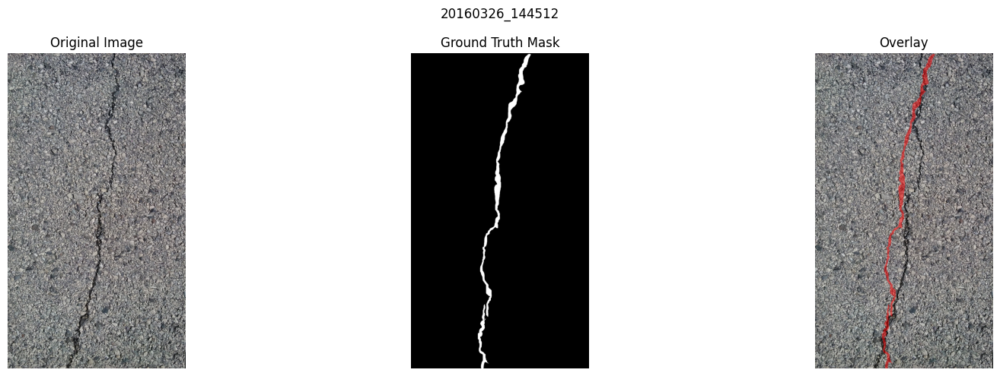

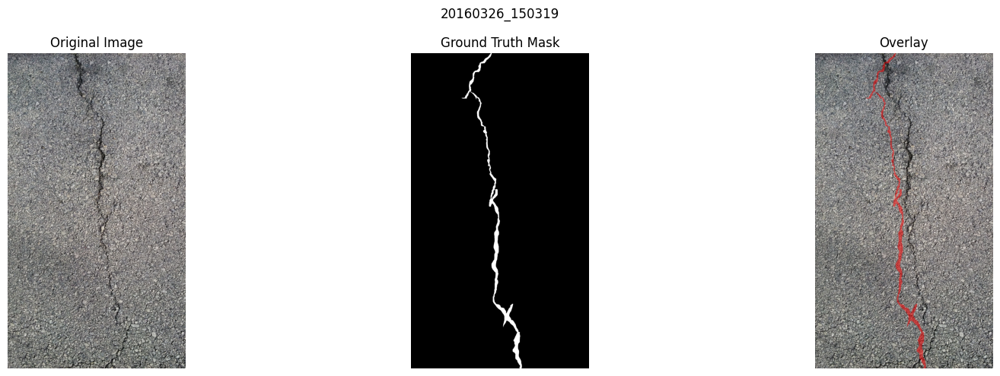

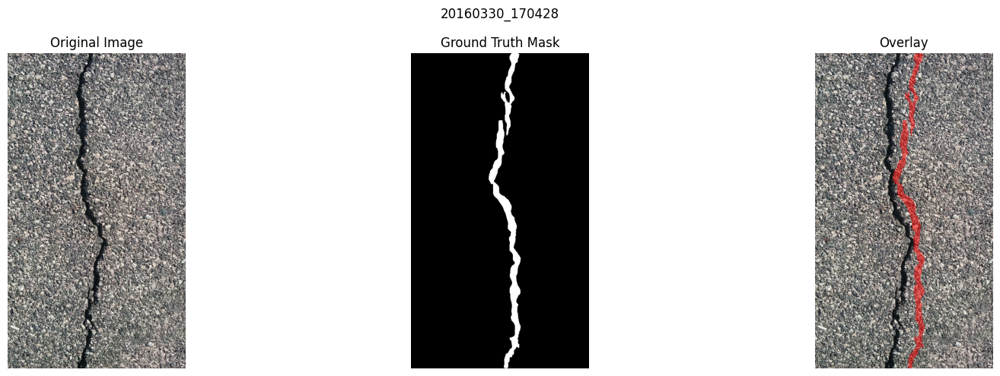

In [33]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

base = Path("/content/InfraScan/datasets/CRACK500/traindata/traindata")

samples = [
    "20160326_144512",
    "20160326_150319",
    "20160330_170428"
]

for name in samples:
    image = np.array(
        Image.open(base / f"{name}.jpg").convert("RGB")
    )

    mask = np.array(
        Image.open(base / f"{name}_mask.png")
    )

    if mask.shape != image.shape[:2]:
        mask = np.rot90(mask)

    overlay = image.copy()
    overlay[mask.astype(bool)] = (
        0.5 * overlay[mask.astype(bool)] +
        0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].imshow(image)
    axes[0].set_title("Original Image")

    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("Ground Truth Mask")

    axes[2].imshow(overlay)
    axes[2].set_title("Overlay")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

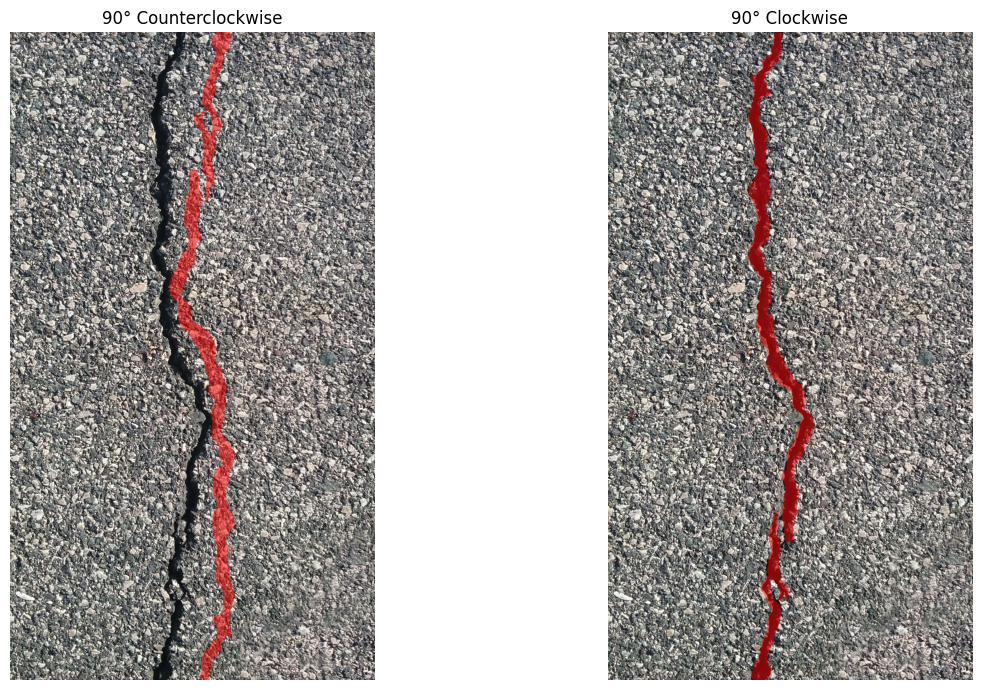

In [34]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

base = Path(
    "/content/InfraScan/datasets/CRACK500/traindata/traindata"
)

name = "20160330_170428"

image = np.array(
    Image.open(base / f"{name}.jpg").convert("RGB")
)

original_mask = np.array(
    Image.open(base / f"{name}_mask.png")
)

mask_ccw = np.rot90(original_mask, k=1)
mask_cw = np.rot90(original_mask, k=3)

def create_overlay(image, mask):
    overlay = image.copy()
    overlay[mask.astype(bool)] = (
        0.5 * overlay[mask.astype(bool)] +
        0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)
    return overlay

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(create_overlay(image, mask_ccw))
axes[0].set_title("90° Counterclockwise")

axes[1].imshow(create_overlay(image, mask_cw))
axes[1].set_title("90° Clockwise")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

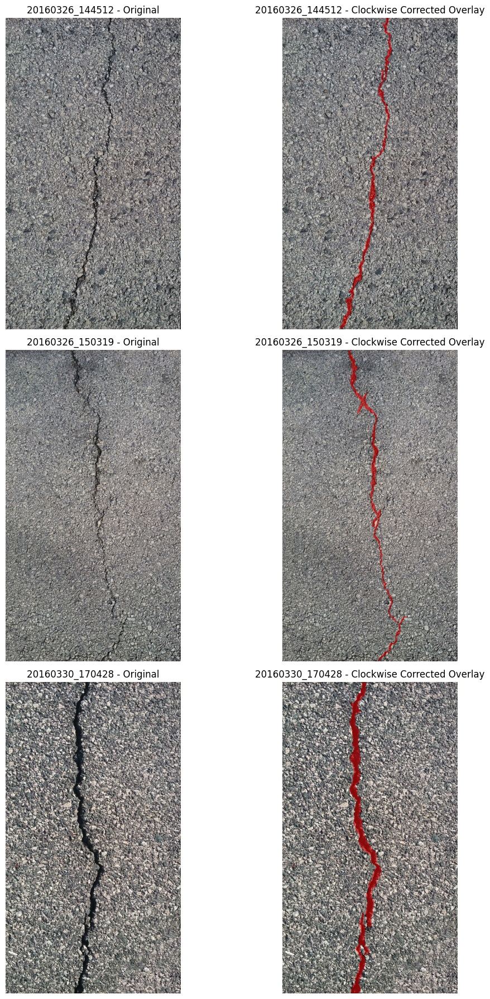

In [35]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

base = Path("/content/InfraScan/datasets/CRACK500/traindata/traindata")

samples = [
    "20160326_144512",
    "20160326_150319",
    "20160330_170428"
]

fig, axes = plt.subplots(3, 2, figsize=(12, 18))

for i, name in enumerate(samples):
    image = np.array(
        Image.open(base / f"{name}.jpg").convert("RGB")
    )

    mask = np.array(
        Image.open(base / f"{name}_mask.png")
    )

    if mask.shape != image.shape[:2]:
        mask = np.rot90(mask, k=3)

    overlay = image.copy()
    overlay[mask.astype(bool)] = (
        0.5 * overlay[mask.astype(bool)] +
        0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"{name} - Original")

    axes[i, 1].imshow(overlay)
    axes[i, 1].set_title(f"{name} - Clockwise Corrected Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [36]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/InfraScan")
DATASET_DIR = PROJECT_DIR / "datasets"
MANIFEST_DIR = PROJECT_DIR / "manifests"

MANIFEST_DIR.mkdir(parents=True, exist_ok=True)

records = []

# --------------------------------------------------
# 1. Concrete Crack Images for Classification
# --------------------------------------------------

concrete_dir = (
    DATASET_DIR
    / "Concrete_Crack_Classification"
    / "Concrete Crack Images for Classification"
)

class_mapping = {
    "Negative": 0,
    "Positive": 1
}

for class_name, label in class_mapping.items():
    class_dir = concrete_dir / class_name

    for image_path in class_dir.rglob("*"):
        if image_path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            records.append({
                "dataset": "Concrete_Crack",
                "image_path": str(image_path),
                "label": class_name,
                "label_id": label,
                "surface": "Concrete",
                "split": None
            })

# --------------------------------------------------
# 2. SDNET2018
# --------------------------------------------------

sdnet_dir = DATASET_DIR / "SDNET2018"

sdnet_mapping = {
    "D": {"C": ("Cracked", 1), "U": ("Uncracked", 0)},
    "P": {"C": ("Cracked", 1), "U": ("Uncracked", 0)},
    "W": {"C": ("Cracked", 1), "U": ("Uncracked", 0)}
}

for surface, classes in sdnet_mapping.items():
    for prefix, (label_name, label_id) in classes.items():

        class_dir = sdnet_dir / surface / f"{prefix}{surface}"

        for image_path in class_dir.rglob("*"):
            if image_path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
                records.append({
                    "dataset": "SDNET2018",
                    "image_path": str(image_path),
                    "label": label_name,
                    "label_id": label_id,
                    "surface": surface,
                    "split": None
                })

# --------------------------------------------------
# 3. Create and save manifest
# --------------------------------------------------

classification_df = pd.DataFrame(records)

classification_df = classification_df.sort_values(
    ["dataset", "label", "image_path"]
).reset_index(drop=True)

output_path = MANIFEST_DIR / "classification_manifest.csv"

classification_df.to_csv(output_path, index=False)

# --------------------------------------------------
# 4. Verification
# --------------------------------------------------

print("CLASSIFICATION MANIFEST CREATED")
print("-" * 45)

print("Total records:", len(classification_df))
print("Missing image paths:",
      sum(not Path(p).is_file() for p in classification_df["image_path"]))

print("\nDataset distribution:")
print(classification_df["dataset"].value_counts())

print("\nClass distribution:")
print(
    classification_df.groupby(["dataset", "label"])
    .size()
    .unstack(fill_value=0)
)

print("\nSurface distribution:")
print(
    classification_df.groupby(["dataset", "surface"])
    .size()
)

print("\nSaved to:", output_path)

CLASSIFICATION MANIFEST CREATED
---------------------------------------------
Total records: 56092
Missing image paths: 0

Dataset distribution:
dataset
SDNET2018    56092
Name: count, dtype: int64

Class distribution:
label      Cracked  Uncracked
dataset                      
SDNET2018     8484      47608

Surface distribution:
dataset    surface
SDNET2018  D          13620
           P          24334
           W          18138
dtype: int64

Saved to: /content/InfraScan/manifests/classification_manifest.csv


In [37]:
from pathlib import Path
from PIL import Image
import pandas as pd

BASE_DIR = Path("/content/InfraScan/datasets/CRACK500")
MANIFEST_DIR = Path("/content/InfraScan/manifests")
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)

# Six image IDs duplicated across the original splits
EXCLUDED_TEST_IDS = {
    "20160328_154452",
    "20160328_154454",
    "20160329_103609",
    "20160329_103800",
    "20160329_111111",
    "20160329_103807"
}

# Three training masks requiring clockwise rotation
ROTATION_FIXES = {
    "20160326_144512": 3,
    "20160326_150319": 3,
    "20160330_170428": 3
}

records = []

for split in ["traindata", "valdata", "testdata"]:

    folder = BASE_DIR / split / split

    for image_path in sorted(folder.glob("*.jpg")):

        image_id = image_path.stem

        # Exclude duplicated images from the test split
        if split == "testdata" and image_id in EXCLUDED_TEST_IDS:
            continue

        mask_path = folder / f"{image_id}_mask.png"

        # Include only verified image-mask pairs
        if not mask_path.is_file():
            continue

        with Image.open(image_path) as img:
            image_size = img.size

        with Image.open(mask_path) as mask:
            mask_size = mask.size

        rotation_k = ROTATION_FIXES.get(image_id, 0)

        # Check dimensions after the documented correction
        corrected_mask_size = (
            (mask_size[1], mask_size[0])
            if rotation_k in (1, 3)
            else mask_size
        )

        if image_size != corrected_mask_size:
            raise ValueError(
                f"Dimension mismatch: {image_id} | "
                f"Image: {image_size} | "
                f"Corrected mask: {corrected_mask_size}"
            )

        records.append({
            "dataset": "CRACK500",
            "image_id": image_id,
            "image_path": str(image_path),
            "mask_path": str(mask_path),
            "split": split.replace("data", ""),
            "rotation_k": rotation_k
        })

segmentation_df = pd.DataFrame(records)

output_path = MANIFEST_DIR / "crack500_segmentation_manifest.csv"

segmentation_df.to_csv(output_path, index=False)

# Verification
print("CRACK500 SEGMENTATION MANIFEST")
print("-" * 45)

print("Total image-mask pairs:", len(segmentation_df))

print("\nSplit distribution:")
print(segmentation_df["split"].value_counts())

print("\nOrientation corrections:")
print(segmentation_df["rotation_k"].value_counts().sort_index())

print("\nMissing image paths:",
      sum(not Path(p).is_file() for p in segmentation_df["image_path"]))

print("Missing mask paths:",
      sum(not Path(p).is_file() for p in segmentation_df["mask_path"]))

print("\nDuplicate image IDs:",
      segmentation_df["image_id"].duplicated().sum())

print("\nSaved to:", output_path)

CRACK500 SEGMENTATION MANIFEST
---------------------------------------------
Total image-mask pairs: 442

Split distribution:
split
train    250
test     142
val       50
Name: count, dtype: int64

Orientation corrections:
rotation_k
0    439
3      3
Name: count, dtype: int64

Missing image paths: 0
Missing mask paths: 0

Duplicate image IDs: 0

Saved to: /content/InfraScan/manifests/crack500_segmentation_manifest.csv


In [38]:
#Create the CrackForest manifest
from pathlib import Path
from PIL import Image
import pandas as pd

BASE_DIR = Path("/content/InfraScan/datasets/CrackForest")
MANIFEST_DIR = Path("/content/InfraScan/manifests")

records = []

image_dir = BASE_DIR / "image"
mat_dir = BASE_DIR / "groundTruth"
seg_dir = BASE_DIR / "seg"

for image_path in sorted(image_dir.glob("*.jpg")):

    image_id = image_path.stem
    mat_path = mat_dir / f"{image_id}.mat"
    seg_path = seg_dir / f"{image_id}.seg"

    # Keep only images with both annotation files
    if not mat_path.is_file() or not seg_path.is_file():
        continue

    with Image.open(image_path) as img:
        width, height = img.size

    records.append({
        "dataset": "CrackForest",
        "image_id": image_id,
        "image_path": str(image_path),
        "mat_path": str(mat_path),
        "seg_path": str(seg_path),
        "width": width,
        "height": height
    })

crackforest_df = pd.DataFrame(records)

output_path = MANIFEST_DIR / "crackforest_segmentation_manifest.csv"

crackforest_df.to_csv(output_path, index=False)

# Verification
print("CRACKFOREST SEGMENTATION MANIFEST")
print("-" * 45)

print("Total matched image-annotation pairs:", len(crackforest_df))

print("\nImage dimensions:")
print(
    crackforest_df.groupby(["width", "height"])
    .size()
)

print("\nMissing image paths:",
      sum(not Path(p).is_file() for p in crackforest_df["image_path"]))

print("Missing MAT paths:",
      sum(not Path(p).is_file() for p in crackforest_df["mat_path"]))

print("Missing SEG paths:",
      sum(not Path(p).is_file() for p in crackforest_df["seg_path"]))

print("\nDuplicate image IDs:",
      crackforest_df["image_id"].duplicated().sum())

print("\nSaved to:", output_path)

CRACKFOREST SEGMENTATION MANIFEST
---------------------------------------------
Total matched image-annotation pairs: 118

Image dimensions:
width  height
480    320       118
dtype: int64

Missing image paths: 0
Missing MAT paths: 0
Missing SEG paths: 0

Duplicate image IDs: 0

Saved to: /content/InfraScan/manifests/crackforest_segmentation_manifest.csv


In [39]:
#Inspect CrackForest annotations
from pathlib import Path
import scipy.io as sio
import numpy as np

base = Path("/content/InfraScan/datasets/CrackForest")

# Select one matched sample
image_id = "001"

mat_path = base / "groundTruth" / f"{image_id}.mat"
seg_path = base / "seg" / f"{image_id}.seg"

# ---------------------------------------
# 1. Inspect MAT annotation
# ---------------------------------------

print("=" * 20, "MAT FILE", "=" * 20)

mat_data = sio.loadmat(mat_path)

for key, value in mat_data.items():
    if not key.startswith("__"):
        print(f"\nVariable: {key}")
        print("Type:", type(value))
        print("Shape:", np.shape(value))

        if isinstance(value, np.ndarray):
            print("Data type:", value.dtype)

            if value.size < 30:
                print("Values:", value)
            elif np.issubdtype(value.dtype, np.number):
                print("Min:", np.nanmin(value))
                print("Max:", np.nanmax(value))

# ---------------------------------------
# 2. Inspect SEG annotation
# ---------------------------------------

print("\n" + "=" * 20, "SEG FILE", "=" * 20)

with open(seg_path, "rb") as f:
    seg_content = f.read(1000)

print("File size:", seg_path.stat().st_size, "bytes")
print("First 1000 bytes:")
print(repr(seg_content))

==================== MAT FILE ====================

Variable: groundTruth
Type: <class 'numpy.ndarray'>
Shape: (1, 1)
Data type: [('Segmentation', 'O'), ('Boundaries', 'O')]
Values: [[(array([[1, 1, 1, ..., 1, 1, 1],
         [1, 1, 1, ..., 1, 1, 1],
         [1, 1, 1, ..., 1, 1, 1],
         ...,
         [1, 1, 1, ..., 1, 1, 1],
         [1, 1, 1, ..., 1, 1, 1],
         [1, 1, 1, ..., 1, 1, 1]], dtype=uint8), array([[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]], dtype=uint8))                                ]]

==================== SEG FILE ====================
File size: 8938 bytes
First 1000 bytes:
b'image C:\\Users\\lenovo\\Desktop\\crack image\\image\\001.jpg\nwidth 480\nheight 320\nsegments 2\ngray 1\ninvert 0\nflipflop 0\nformat ascii cr\ndata\n0 0 0 479\n0 1 0 479\n0 2 0 479\n0 3 0 479\n0 4 0 479\n0 5 0 479\n0 6 0 47

In [40]:
#extract and inspect the MAT arrays
import scipy.io as sio
import numpy as np

mat_path = (
    "/content/InfraScan/datasets/CrackForest/"
    "groundTruth/001.mat"
)

data = sio.loadmat(mat_path)

ground_truth = data["groundTruth"][0, 0]

segmentation = ground_truth["Segmentation"][0, 0]
boundaries = ground_truth["Boundaries"][0, 0]

print("SEGMENTATION")
print("Shape:", segmentation.shape)
print("Data type:", segmentation.dtype)
print("Unique values:", np.unique(segmentation))
print("Value distribution:", np.unique(segmentation, return_counts=True))

print("\nBOUNDARIES")
print("Shape:", boundaries.shape)
print("Data type:", boundaries.dtype)
print("Unique values:", np.unique(boundaries))
print("Value distribution:", np.unique(boundaries, return_counts=True))

SEGMENTATION
Shape: ()
Data type: uint8
Unique values: [1]
Value distribution: (array([1], dtype=uint8), array([1]))

BOUNDARIES
Shape: ()
Data type: uint8
Unique values: [0]
Value distribution: (array([0], dtype=uint8), array([1]))


TypeError: Invalid shape () for image data

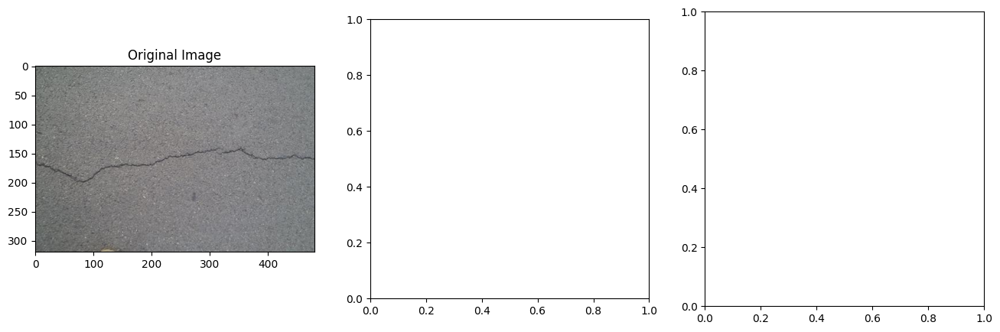

In [41]:
#Visualize the annotations
import matplotlib.pyplot as plt
from PIL import Image

image_path = (
    "/content/InfraScan/datasets/CrackForest/"
    "image/001.jpg"
)

image = np.array(Image.open(image_path).convert("RGB"))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")

axes[1].imshow(segmentation, cmap="gray")
axes[1].set_title("MAT Segmentation")

axes[2].imshow(boundaries, cmap="gray")
axes[2].set_title("MAT Boundaries")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [42]:
import scipy.io as sio
import numpy as np

mat_path = (
    "/content/InfraScan/datasets/CrackForest/"
    "groundTruth/001.mat"
)

data = sio.loadmat(mat_path)
gt = data["groundTruth"]

print("GroundTruth shape:", gt.shape)
print("GroundTruth dtype:", gt.dtype)

print("\nSegmentation field:")
seg_field = gt["Segmentation"]
print("Shape:", seg_field.shape)
print("Type:", type(seg_field[0, 0]))
print("Value:", repr(seg_field[0, 0])[:500])

print("\nBoundaries field:")
boundary_field = gt["Boundaries"]
print("Shape:", boundary_field.shape)
print("Type:", type(boundary_field[0, 0]))
print("Value:", repr(boundary_field[0, 0])[:500])

GroundTruth shape: (1, 1)
GroundTruth dtype: [('Segmentation', 'O'), ('Boundaries', 'O')]

Segmentation field:
Shape: (1, 1)
Type: <class 'numpy.ndarray'>
Value: array([[1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       ...,
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1]], dtype=uint8)

Boundaries field:
Shape: (1, 1)
Type: <class 'numpy.ndarray'>
Value: array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)


In [43]:
import scipy.io as sio
import numpy as np

mat_path = (
    "/content/InfraScan/datasets/CrackForest/"
    "groundTruth/001.mat"
)

data = sio.loadmat(mat_path)

gt = data["groundTruth"][0, 0]

segmentation = gt["Segmentation"][0, 0]
boundaries = gt["Boundaries"][0, 0]

print("SEGMENTATION")
print("Shape:", segmentation.shape)
print("Data type:", segmentation.dtype)
print("Unique values:", np.unique(segmentation))
print("Value counts:", np.unique(segmentation, return_counts=True))

print("\nBOUNDARIES")
print("Shape:", boundaries.shape)
print("Data type:", boundaries.dtype)
print("Unique values:", np.unique(boundaries))
print("Value counts:", np.unique(boundaries, return_counts=True))

SEGMENTATION
Shape: ()
Data type: uint8
Unique values: [1]
Value counts: (array([1], dtype=uint8), array([1]))

BOUNDARIES
Shape: ()
Data type: uint8
Unique values: [0]
Value counts: (array([0], dtype=uint8), array([1]))


In [44]:
import scipy.io as sio
import numpy as np

mat_path = (
    "/content/InfraScan/datasets/CrackForest/"
    "groundTruth/001.mat"
)

data = sio.loadmat(mat_path)

# Keep the outer structured array intact
gt = data["groundTruth"]

# Extract the complete 2D arrays
segmentation = gt["Segmentation"][0, 0]
boundaries = gt["Boundaries"][0, 0]

print("SEGMENTATION")
print("Shape:", segmentation.shape)
print("Data type:", segmentation.dtype)
print("Unique values:", np.unique(segmentation))
print("Value counts:", np.unique(segmentation, return_counts=True))

print("\nBOUNDARIES")
print("Shape:", boundaries.shape)
print("Data type:", boundaries.dtype)
print("Unique values:", np.unique(boundaries))
print("Value counts:", np.unique(boundaries, return_counts=True))

SEGMENTATION
Shape: (320, 480)
Data type: uint8
Unique values: [1 2]
Value counts: (array([1, 2], dtype=uint8), array([151769,   1831]))

BOUNDARIES
Shape: (320, 480)
Data type: uint8
Unique values: [0 1]
Value counts: (array([0, 1], dtype=uint8), array([152423,   1177]))


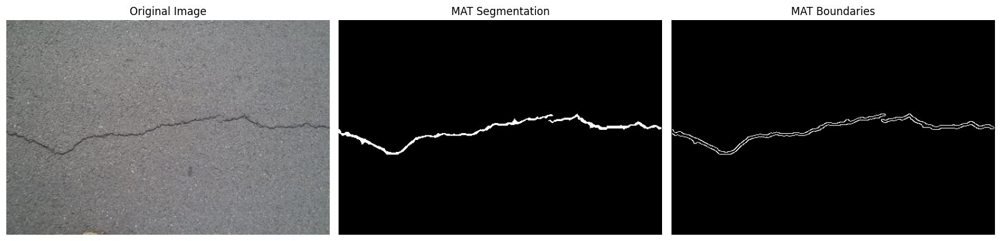

In [45]:
import matplotlib.pyplot as plt
from PIL import Image

image_path = (
    "/content/InfraScan/datasets/CrackForest/"
    "image/001.jpg"
)

image = np.array(Image.open(image_path).convert("RGB"))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")

axes[1].imshow(segmentation, cmap="gray")
axes[1].set_title("MAT Segmentation")

axes[2].imshow(boundaries, cmap="gray")
axes[2].set_title("MAT Boundaries")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [46]:
#Validating all CrackForest MAT annotations
from pathlib import Path
import scipy.io as sio
import numpy as np

mat_dir = Path(
    "/content/InfraScan/datasets/CrackForest/groundTruth"
)

results = []
errors = []

for mat_path in sorted(mat_dir.glob("*.mat")):
    try:
        data = sio.loadmat(mat_path)
        gt = data["groundTruth"]

        segmentation = gt["Segmentation"][0, 0]
        boundaries = gt["Boundaries"][0, 0]

        results.append({
            "image_id": mat_path.stem,
            "seg_shape": segmentation.shape,
            "boundary_shape": boundaries.shape,
            "seg_values": tuple(np.unique(segmentation)),
            "boundary_values": tuple(np.unique(boundaries))
        })

    except Exception as e:
        errors.append((mat_path.name, str(e)))

print("MAT files checked:", len(results))
print("Errors:", len(errors))

if results:
    print("\nSegmentation dimensions:")
    print(set(r["seg_shape"] for r in results))

    print("\nBoundary dimensions:")
    print(set(r["boundary_shape"] for r in results))

    print("\nSegmentation value patterns:")
    print(set(r["seg_values"] for r in results))

    print("\nBoundary value patterns:")
    print(set(r["boundary_values"] for r in results))

if errors:
    print("\nError details:")
    for error in errors[:10]:
        print(error)

MAT files checked: 118
Errors: 0

Segmentation dimensions:
{(320, 480)}

Boundary dimensions:
{(320, 480)}

Segmentation value patterns:
{(np.uint8(1), np.uint8(2), np.uint8(3), np.uint8(4)), (np.uint8(1), np.uint8(2)), (np.uint8(1), np.uint8(2), np.uint8(3))}

Boundary value patterns:
{(np.uint8(0), np.uint8(1))}


In [47]:
#class distributions across all annotations
from pathlib import Path
import scipy.io as sio
import numpy as np
import pandas as pd

mat_dir = Path(
    "/content/InfraScan/datasets/CrackForest/groundTruth"
)

records = []

for mat_path in sorted(mat_dir.glob("*.mat")):

    data = sio.loadmat(mat_path)
    gt = data["groundTruth"]

    segmentation = gt["Segmentation"][0, 0]

    values, counts = np.unique(
        segmentation,
        return_counts=True
    )

    row = {"image_id": mat_path.stem}

    for value, count in zip(values, counts):
        row[f"class_{value}_pixels"] = int(count)

    records.append(row)

class_distribution = pd.DataFrame(records).fillna(0)

print("PIXEL DISTRIBUTION ACROSS 118 MAT FILES")
print("-" * 50)

pixel_columns = [
    col for col in class_distribution.columns
    if col.endswith("_pixels")
]

print("\nTotal pixels per class:")
print(class_distribution[pixel_columns].sum())

print("\nNumber of images containing each class:")
print((class_distribution[pixel_columns] > 0).sum())

print("\nSample annotation distributions:")
print(class_distribution.head(10).to_string(index=False))

PIXEL DISTRIBUTION ACROSS 118 MAT FILES
--------------------------------------------------

Total pixels per class:
class_1_pixels    17710362.0
class_2_pixels      292885.0
class_3_pixels      120201.0
class_4_pixels        1352.0
dtype: float64

Number of images containing each class:
class_1_pixels    118
class_2_pixels    118
class_3_pixels     22
class_4_pixels      5
dtype: int64

Sample annotation distributions:
image_id  class_1_pixels  class_2_pixels  class_3_pixels  class_4_pixels
     001          151769            1831             0.0             0.0
     002          148601            4999             0.0             0.0
     003          151171            2429             0.0             0.0
     004          151583            2017             0.0             0.0
     005          151859            1741             0.0             0.0
     006          151869            1731             0.0             0.0
     007          152184            1416             0.0          

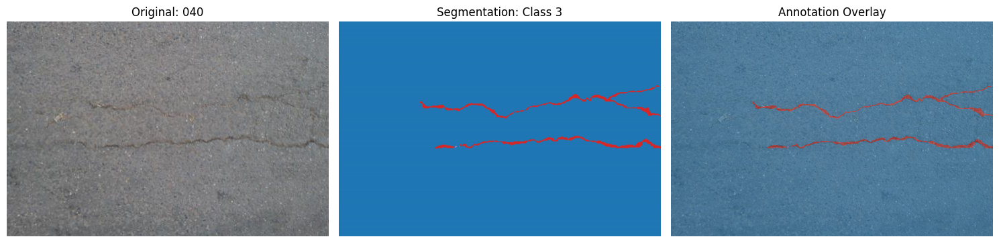

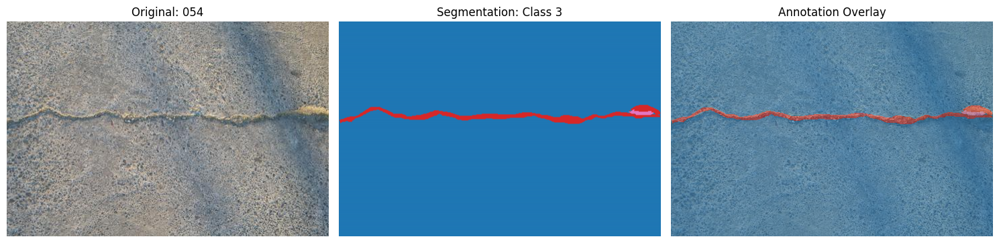

In [48]:
from pathlib import Path
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

base = Path("/content/InfraScan/datasets/CrackForest")

# Find representative images containing classes 3 and 4
selected = []

for mat_path in sorted((base / "groundTruth").glob("*.mat")):

    gt = sio.loadmat(mat_path)["groundTruth"]
    segmentation = gt["Segmentation"][0, 0]

    values = set(np.unique(segmentation))

    if 4 in values and 3 in values:
        selected.append((mat_path.stem, segmentation, "Classes 3 and 4"))
    elif 3 in values and not any(x[2] == "Classes 3 and 4" for x in selected):
        selected.append((mat_path.stem, segmentation, "Class 3"))

    if len(selected) >= 2:
        break

for image_id, segmentation, description in selected:

    image = np.array(
        Image.open(base / "image" / f"{image_id}.jpg").convert("RGB")
    )

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(image)
    axes[0].set_title(f"Original: {image_id}")

    axes[1].imshow(segmentation, cmap="tab10", vmin=1, vmax=4)
    axes[1].set_title(f"Segmentation: {description}")

    axes[2].imshow(image)
    axes[2].imshow(
        segmentation,
        cmap="tab10",
        vmin=1,
        vmax=4,
        alpha=0.5
    )
    axes[2].set_title("Annotation Overlay")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

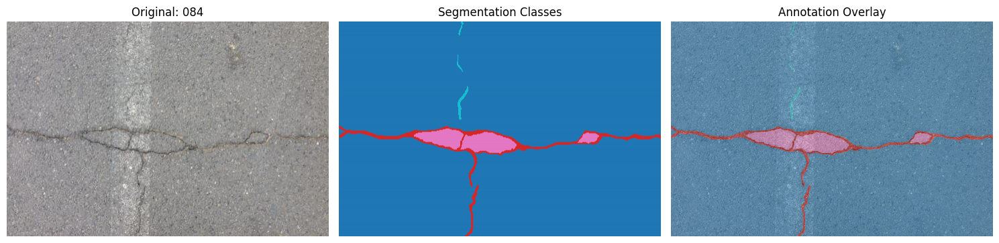

Image ID: 084
Class distribution: (array([1, 2, 3, 4], dtype=uint8), array([146435,   3359,   3506,    300]))


In [49]:
#inspecting class 4
from pathlib import Path
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

base = Path("/content/InfraScan/datasets/CrackForest")

for mat_path in sorted((base / "groundTruth").glob("*.mat")):
    gt = sio.loadmat(mat_path)["groundTruth"]
    segmentation = gt["Segmentation"][0, 0]

    if 4 in np.unique(segmentation):
        image_id = mat_path.stem

        image = np.array(
            Image.open(
                base / "image" / f"{image_id}.jpg"
            ).convert("RGB")
        )

        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        axes[0].imshow(image)
        axes[0].set_title(f"Original: {image_id}")

        axes[1].imshow(segmentation, cmap="tab10", vmin=1, vmax=4)
        axes[1].set_title("Segmentation Classes")

        axes[2].imshow(image)
        axes[2].imshow(
            segmentation,
            cmap="tab10",
            vmin=1,
            vmax=4,
            alpha=0.5
        )
        axes[2].set_title("Annotation Overlay")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()
        plt.show()

        print("Image ID:", image_id)
        print("Class distribution:",
              np.unique(segmentation, return_counts=True))
        break

In [50]:
#inspecting all 5 of class 4
from pathlib import Path
import scipy.io as sio
import numpy as np
import pandas as pd

mat_dir = Path(
    "/content/InfraScan/datasets/CrackForest/groundTruth"
)

records = []

for mat_path in sorted(mat_dir.glob("*.mat")):
    gt = sio.loadmat(mat_path)["groundTruth"]
    segmentation = gt["Segmentation"][0, 0]

    count = np.count_nonzero(segmentation == 4)

    if count > 0:
        records.append({
            "image_id": mat_path.stem,
            "class_4_pixels": count,
            "class_2_pixels": np.count_nonzero(segmentation == 2),
            "class_3_pixels": np.count_nonzero(segmentation == 3)
        })

class4_df = pd.DataFrame(records)

print(class4_df.to_string(index=False))

image_id  class_4_pixels  class_2_pixels  class_3_pixels
     084             300            3359            3506
     102             437            2258            1868
     107             388            1825             151
     111             101            1597              12
     117             126            2130             296


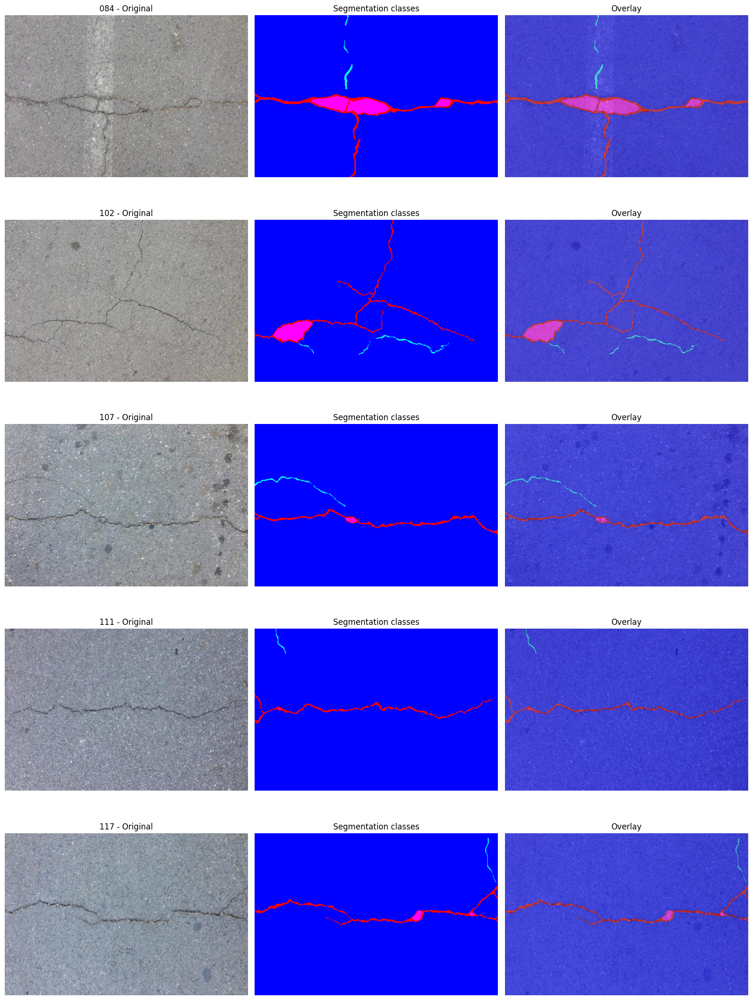

In [51]:
from pathlib import Path
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.colors import ListedColormap

base = Path("/content/InfraScan/datasets/CrackForest")

image_ids = ["084", "102", "107", "111", "117"]

cmap = ListedColormap([
    "black", "blue", "red", "magenta", "cyan"
])

fig, axes = plt.subplots(5, 3, figsize=(16, 22))

for i, image_id in enumerate(image_ids):

    image = np.array(
        Image.open(base / "image" / f"{image_id}.jpg").convert("RGB")
    )

    gt = sio.loadmat(
        base / "groundTruth" / f"{image_id}.mat"
    )["groundTruth"]

    segmentation = gt["Segmentation"][0, 0]

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"{image_id} - Original")

    axes[i, 1].imshow(segmentation, cmap=cmap, vmin=0, vmax=4)
    axes[i, 1].set_title("Segmentation classes")

    axes[i, 2].imshow(image)
    axes[i, 2].imshow(
        segmentation,
        cmap=cmap,
        vmin=0,
        vmax=4,
        alpha=0.55
    )
    axes[i, 2].set_title("Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [52]:
from pathlib import Path
import scipy.io as sio
import numpy as np
import pandas as pd

mat_dir = Path(
    "/content/InfraScan/datasets/CrackForest/groundTruth"
)

results = []

for mat_path in sorted(mat_dir.glob("*.mat")):

    gt = sio.loadmat(mat_path)["groundTruth"]
    segmentation = gt["Segmentation"][0, 0]

    binary_mask = (segmentation != 1).astype(np.uint8)

    results.append({
        "image_id": mat_path.stem,
        "total_pixels": binary_mask.size,
        "crack_pixels": int(binary_mask.sum()),
        "background_pixels": int((binary_mask == 0).sum()),
        "mask_values": tuple(np.unique(binary_mask))
    })

df = pd.DataFrame(results)

print("CRACKFOREST BINARY MASK VALIDATION")
print("-" * 45)

print("Images checked:", len(df))
print("Total crack pixels:", df["crack_pixels"].sum())
print("Total background pixels:", df["background_pixels"].sum())
print("Images with binary values:",
      (df["mask_values"] == (0, 1)).sum())

print("\nSample results:")
print(df.head(10).to_string(index=False))

CRACKFOREST BINARY MASK VALIDATION
---------------------------------------------
Images checked: 118
Total crack pixels: 414438
Total background pixels: 17710362
Images with binary values: 118

Sample results:
image_id  total_pixels  crack_pixels  background_pixels mask_values
     001        153600          1831             151769      (0, 1)
     002        153600          4999             148601      (0, 1)
     003        153600          2429             151171      (0, 1)
     004        153600          2017             151583      (0, 1)
     005        153600          1741             151859      (0, 1)
     006        153600          1731             151869      (0, 1)
     007        153600          1416             152184      (0, 1)
     008        153600          2562             151038      (0, 1)
     009        153600          2031             151569      (0, 1)
     010        153600          1953             151647      (0, 1)


In [53]:
import pandas as pd
from pathlib import Path

MANIFEST_DIR = Path("/content/InfraScan/manifests")
BASE_DIR = Path("/content/InfraScan/datasets/CrackForest")
OUTPUT_DIR = Path("/content/InfraScan/processed/CrackForest/masks")

manifest_path = MANIFEST_DIR / "crackforest_segmentation_manifest.csv"

existing_manifest = pd.read_csv(
    manifest_path,
    dtype={"image_id": str}
)

# Preserve three-digit IDs: 1 -> 001
existing_manifest["image_id"] = (
    existing_manifest["image_id"].str.zfill(3)
)

records = []

for mask_path in sorted(OUTPUT_DIR.glob("*_mask.png")):

    image_id = mask_path.stem.replace("_mask", "")

    from PIL import Image
    import numpy as np

    mask = np.array(Image.open(mask_path))

    records.append({
        "image_id": image_id,
        "mask_path": str(mask_path),
        "crack_pixels": int(np.count_nonzero(mask)),
        "background_pixels": int(np.count_nonzero(mask == 0))
    })

mask_df = pd.DataFrame(records)
mask_df["image_id"] = mask_df["image_id"].astype(str).str.zfill(3)

updated_manifest = existing_manifest.merge(
    mask_df,
    on="image_id",
    how="left",
    validate="one_to_one"
)

assert len(updated_manifest) == 118
assert updated_manifest["mask_path"].notna().all()

updated_manifest.to_csv(manifest_path, index=False)

print("CRACKFOREST MANIFEST UPDATED")
print("-" * 40)
print("Total records:", len(updated_manifest))
print("Missing mask paths:", updated_manifest["mask_path"].isna().sum())
print("Generated masks:", len(list(OUTPUT_DIR.glob("*_mask.png"))))
print("Total crack pixels:", updated_manifest["crack_pixels"].sum())
print("Total background pixels:", updated_manifest["background_pixels"].sum())
print("\nSaved:", manifest_path)

KeyError: 'image_id'

In [54]:
#Standardize CRACK500 masks
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

PROJECT_DIR = Path("/content/InfraScan")
MANIFEST_DIR = PROJECT_DIR / "manifests"

manifest_path = MANIFEST_DIR / "crack500_segmentation_manifest.csv"

OUTPUT_DIR = PROJECT_DIR / "processed/CRACK500/masks"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(manifest_path, dtype={"image_id": str})

records = []

for _, row in df.iterrows():

    image_id = row["image_id"]
    image_path = Path(row["image_path"])
    original_mask_path = Path(row["mask_path"])

    # Load original mask
    mask = np.array(Image.open(original_mask_path))

    # Apply documented orientation correction
    rotation_k = int(row["rotation_k"])

    if rotation_k != 0:
        mask = np.rot90(mask, k=rotation_k)

    # Convert to binary: background 0, crack 255
    binary_mask = (mask > 0).astype(np.uint8) * 255

    # Verify dimensions against original image
    with Image.open(image_path) as img:
        expected_shape = (img.height, img.width)

    if binary_mask.shape != expected_shape:
        raise ValueError(
            f"Dimension mismatch for {image_id}: "
            f"{binary_mask.shape} != {expected_shape}"
        )

    output_path = OUTPUT_DIR / f"{image_id}_mask.png"
    Image.fromarray(binary_mask).save(output_path)

    records.append({
        "image_id": image_id,
        "processed_mask_path": str(output_path),
        "crack_pixels": int(np.count_nonzero(binary_mask)),
        "background_pixels": int(np.count_nonzero(binary_mask == 0)),
        "mask_height": binary_mask.shape[0],
        "mask_width": binary_mask.shape[1]
    })

processed_df = pd.DataFrame(records)

df = df.merge(
    processed_df,
    on="image_id",
    how="left",
    validate="one_to_one"
)

assert len(df) == 442
assert df["processed_mask_path"].notna().all()

df.to_csv(manifest_path, index=False)

print("CRACK500 MASK STANDARDIZATION")
print("-" * 45)

print("Processed masks:", len(processed_df))
print("Missing processed masks:",
      sum(not Path(p).is_file()
          for p in processed_df["processed_mask_path"]))

print("\nSplit distribution:")
print(df["split"].value_counts())

print("\nOrientation corrections:")
print(df["rotation_k"].value_counts().sort_index())

print("\nTotal crack pixels:", processed_df["crack_pixels"].sum())
print("Total background pixels:", processed_df["background_pixels"].sum())

print("\nUpdated manifest:", manifest_path)

CRACK500 MASK STANDARDIZATION
---------------------------------------------
Processed masks: 442
Missing processed masks: 0

Split distribution:
split
train    250
test     142
val       50
Name: count, dtype: int64

Orientation corrections:
rotation_k
0    439
3      3
Name: count, dtype: int64

Total crack pixels: 46653872
Total background pixels: 1600047184

Updated manifest: /content/InfraScan/manifests/crack500_segmentation_manifest.csv


In [56]:
#Create a unified segmentation manifest
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

PROJECT_DIR = Path("/content/InfraScan")
MANIFEST_DIR = PROJECT_DIR / "manifests"

# -----------------------------------------
# 1. Load existing manifests
# -----------------------------------------

crack500 = pd.read_csv(
    MANIFEST_DIR / "crack500_segmentation_manifest.csv"
)

crackforest = pd.read_csv(
    MANIFEST_DIR / "crackforest_segmentation_manifest.csv",
    dtype={"image_id": str}
)

# -----------------------------------------
# 2. Standardize CRACK500 columns
# -----------------------------------------

crack500_unified = pd.DataFrame({
    "dataset": "CRACK500",
    "image_id": crack500["image_id"].astype(str),
    "image_path": crack500["image_path"],
    "mask_path": crack500["processed_mask_path"],
    "split": crack500["split"],
    "mask_height": crack500["mask_height"],
    "mask_width": crack500["mask_width"],
    "crack_pixels": crack500["crack_pixels"],
    "background_pixels": crack500["background_pixels"]
})

# -----------------------------------------
# 3. Assign reproducible CrackForest splits
# -----------------------------------------

cf = crackforest.copy()

train_ids, remaining_ids = train_test_split(
    cf["image_id"],
    test_size=0.30,
    random_state=42,
    shuffle=True
)

val_ids, test_ids = train_test_split(
    remaining_ids,
    test_size=0.50,
    random_state=42,
    shuffle=True
)

split_mapping = {
    **{x: "train" for x in train_ids},
    **{x: "val" for x in val_ids},
    **{x: "test" for x in test_ids}
}

crackforest_unified = pd.DataFrame({
    "dataset": "CrackForest",
    "image_id": cf["image_id"].astype(str),
    "image_path": cf["image_path"],
    "mask_path": cf["mask_path"],
    "split": cf["image_id"].map(split_mapping),
    "mask_height": cf["height"],
    "mask_width": cf["width"],
    "crack_pixels": cf["crack_pixels"],
    "background_pixels": cf["background_pixels"]
})

# -----------------------------------------
# 4. Combine both datasets
# -----------------------------------------

unified_df = pd.concat(
    [crack500_unified, crackforest_unified],
    ignore_index=True
)

# -----------------------------------------
# 5. Verify and save
# -----------------------------------------

assert len(unified_df) == 560
assert unified_df["image_path"].map(
    lambda p: Path(p).is_file()
).all()
assert unified_df["mask_path"].map(
    lambda p: Path(p).is_file()
).all()
assert not unified_df.duplicated(
    subset=["dataset", "image_id"]
).any()

output_path = MANIFEST_DIR / "unified_segmentation_manifest.csv"

unified_df.to_csv(output_path, index=False)

print("UNIFIED SEGMENTATION MANIFEST")
print("-" * 45)

print("Total samples:", len(unified_df))

print("\nDataset distribution:")
print(unified_df["dataset"].value_counts())

print("\nSplit distribution:")
print(pd.crosstab(
    unified_df["dataset"],
    unified_df["split"]
))

print("\nMissing image paths:",
      sum(not Path(p).is_file()
          for p in unified_df["image_path"]))

print("Missing mask paths:",
      sum(not Path(p).is_file()
          for p in unified_df["mask_path"]))

print("\nSaved to:", output_path)

KeyError: 'mask_path'

In [ ]:
#Image Quality Assessment
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

manifest_path = (
    "/content/InfraScan/manifests/"
    "unified_segmentation_manifest.csv"
)

df = pd.read_csv(manifest_path)

results = []
errors = []

for _, row in df.iterrows():

    image_path = Path(row["image_path"])
    mask_path = Path(row["mask_path"])

    try:
        with Image.open(image_path) as img:
            img.verify()

        with Image.open(image_path) as img:
            image_size = img.size
            image_mode = img.mode

        with Image.open(mask_path) as mask_img:
            mask_img.verify()

        with Image.open(mask_path) as mask_img:
            mask = np.array(mask_img)

        image_shape = (image_size[1], image_size[0])

        if mask.ndim != 2:
            raise ValueError(f"Mask is not grayscale: {mask.shape}")

        if mask.shape != image_shape:
            raise ValueError(
                f"Dimension mismatch: image={image_shape}, "
                f"mask={mask.shape}"
            )

        unique_values = np.unique(mask)

        if not set(unique_values).issubset({0, 255}):
            raise ValueError(
                f"Unexpected mask values: {unique_values}"
            )

        crack_pixels = int(np.count_nonzero(mask))
        total_pixels = int(mask.size)

        results.append({
            "dataset": row["dataset"],
            "split": row["split"],
            "image_id": row["image_id"],
            "width": image_size[0],
            "height": image_size[1],
            "image_mode": image_mode,
            "crack_pixels": crack_pixels,
            "background_pixels": total_pixels - crack_pixels,
            "crack_ratio": crack_pixels / total_pixels
        })

    except Exception as e:
        errors.append({
            "image_id": row["image_id"],
            "dataset": row["dataset"],
            "error": str(e)
        })

quality_df = pd.DataFrame(results)

print("IMAGE QUALITY ASSESSMENT")
print("-" * 45)

print("Total samples:", len(df))
print("Successfully checked:", len(quality_df))
print("Failed samples:", len(errors))

print("\nImage dimensions by dataset:")
print(
    quality_df.groupby(["dataset", "width", "height"])
    .size()
)

print("\nImage color modes:")
print(quality_df.groupby(["dataset", "image_mode"]).size())

print("\nEmpty masks:", (quality_df["crack_pixels"] == 0).sum())

print("\nCrack pixel ratio by dataset:")
print(
    quality_df.groupby("dataset")["crack_ratio"]
    .describe()
)

if errors:
    print("\nFirst 10 errors:")
    print(pd.DataFrame(errors).head(10).to_string(index=False))

quality_output = (
    "/content/InfraScan/manifests/"
    "segmentation_quality_report.csv"
)

quality_df.to_csv(quality_output, index=False)

print("\nQuality report saved to:", quality_output)

In [ ]:
import sys
import os
import torch
import numpy as np
import pandas as pd
import cv2

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("OpenCV:", cv2.__version__)

print("\nGPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nProject directory exists:",
      os.path.exists("/content/InfraScan"))

print("Classification manifest exists:",
      os.path.exists(
          "/content/InfraScan/manifests/classification_manifest.csv"
      ))

print("Segmentation manifest exists:",
      os.path.exists(
          "/content/InfraScan/manifests/unified_segmentation_manifest.csv"
      ))